# Comparative Study of ML and DL Classification Models



## 1. Setup

In [1]:
# Run once per fresh runtime:
# !pip install -q kagglehub imbalanced-learn javalang statsmodels tensorflow

import os, re, time, json, random, warnings, difflib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, matthews_corrcoef)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

QUICK_TEST = True  # True = fast smoke test; False = full Chapter-3 protocol

N_OUTER_ML   = 3 if QUICK_TEST else 10
N_OUTER_DL   = 3 if QUICK_TEST else 10
DL_EPOCHS    = 3 if QUICK_TEST else 30
PC2_REPEATS  = 5
BUGS_PER_PROJECT_LIMIT = 8 if QUICK_TEST else None   # None = every bug folder found

# Speed controls for Pipeline A -- the previous slowness came from looping over
# hundreds of irrelevant files, not from these settings, but keep them modest anyway.
ML_GRID_MODE = "small" if QUICK_TEST else "full"

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("QUICK_TEST =", QUICK_TEST)

QUICK_TEST = True


## 2. GPU check (only Pipeline B / DL benefits from this)

In [2]:
try:
    import tensorflow as tf
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        for g in gpus:
            tf.config.experimental.set_memory_growth(g, True)
        print(f"TensorFlow sees {len(gpus)} GPU(s):", gpus)
    else:
        print("No GPU visible to TensorFlow. On Colab: Runtime -> Change runtime type -> GPU, then restart.")
except ImportError:
    print("TensorFlow not installed yet -- run the pip install cell above.")

TensorFlow sees 1 GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. PROMISE (NASA MDP) acquisition

In [3]:
import kagglehub

def load_arff_or_csv(path):
    if path.lower().endswith(".csv"):
        return pd.read_csv(path)
    cols, rows, in_data = [], [], False
    with open(path, "r", errors="ignore") as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("%"):
                continue
            low = line.lower()
            if low.startswith("@attribute"):
                cols.append(line.split()[1].strip("'\""))
            elif low.startswith("@data"):
                in_data = True
            elif in_data:
                rows.append([v.strip() for v in line.split(",")])
    return pd.DataFrame(rows, columns=cols)

def find_label_col(df):
    candidates = [c for c in df.columns if c.lower() in
                  ("defective", "defects", "defect", "target", "label", "class",
                   "bug", "buggy", "is_buggy", "fault", "faulty")]
    return candidates[0] if candidates else None

def to_binary(series):
    if pd.api.types.is_bool_dtype(series) or pd.api.types.is_numeric_dtype(series):
        return series.astype(float).astype(int)
    pos_vals = {"y", "yes", "true", "1", "defective", "d", "buggy", "b", "true.", "b'yes'"}
    return series.astype(str).str.strip().str.lower().str.strip("'").isin(pos_vals).astype(int)

promise_path = kagglehub.dataset_download("radowanulhaque/software-defect")
print("PROMISE downloaded to:", promise_path)

promise_files = []
for root, _, files in os.walk(promise_path):
    for f in files:
        if f.lower().endswith((".csv", ".arff")):
            promise_files.append(os.path.join(root, f))
print(f"{len(promise_files)} PROMISE file(s) found")

promise_tables, promise_meta = {}, {}
for f in promise_files:
    try:
        df = load_arff_or_csv(f)
        label_col = find_label_col(df)
        if label_col is None:
            continue  # not a labelled defect table -- skip silently, unlike the Defects4J bug above
        name = os.path.splitext(os.path.basename(f))[0]
        promise_tables[name] = df
        promise_meta[name] = dict(label_col=label_col)
        y = to_binary(df[label_col])
        print(f"{name}: n={len(df)}, label='{label_col}', defective={y.sum()}, rate={y.mean()*100:.2f}%")
    except Exception as e:
        print(f"skipped {f}: {e}")

100%|██████████| 308k/308k [00:00<00:00, 438kB/s]

Extracting files...
PROMISE downloaded to: /root/.cache/kagglehub/datasets/radowanulhaque/software-defect/versions/1
2 PROMISE file(s) found
cm1: n=498, label='defects', defective=49, rate=9.84%
jm1: n=10885, label='defects', defective=2106, rate=19.35%


## 4. Defects4J acquisition -- corrected loader (Section 3.3.1)


In [ ]:
d4j_path = kagglehub.dataset_download("arunabhaalphadutta/defects4j-extracted-dataset")
print("Defects4J archive at:", d4j_path)

# Bug folders sit directly under the dataset root (or one level down under versions/N)
def find_bug_root(base):
    for entry in os.scandir(base):
        if entry.is_dir() and re.match(r"^[A-Za-z]+-\d+$", entry.name):
            return base
    for entry in os.scandir(base):
        if entry.is_dir():
            sub = find_bug_root(entry.path)
            if sub:
                return sub
    return None

bug_root = find_bug_root(d4j_path)
print("Bug folders located at:", bug_root)

bug_pairs = []
for entry in sorted(os.scandir(bug_root), key=lambda e: e.name):
    if not entry.is_dir() or not re.match(r"^[A-Za-z]+-\d+$", entry.name):
        continue
    buggy_dir = os.path.join(entry.path, "buggy")
    fixed_dir = os.path.join(entry.path, "fixed")
    if os.path.isdir(buggy_dir) and os.path.isdir(fixed_dir):
        project = re.match(r"^([A-Za-z]+)-\d+$", entry.name).group(1)
        bug_pairs.append(dict(bug_id=entry.name, project=project, buggy=buggy_dir, fixed=fixed_dir))

print(f"{len(bug_pairs)} buggy/fixed bug folder pairs found")

if BUGS_PER_PROJECT_LIMIT is not None:
    from collections import defaultdict
    capped, counts = [], defaultdict(int)
    for bp in bug_pairs:
        if counts[bp["project"]] < BUGS_PER_PROJECT_LIMIT:
            capped.append(bp)
            counts[bp["project"]] += 1
    bug_pairs = capped
    print(f"capped to {len(bug_pairs)} bug pairs (QUICK_TEST={QUICK_TEST})")

pd.Series([bp["project"] for bp in bug_pairs]).value_counts()

100%|██████████| 15.7G/15.7G [12:44<00:00, 22.1MB/s]

Extracting files...


Defects4J archive at: /root/.cache/kagglehub/datasets/arunabhaalphadutta/defects4j-extracted-dataset/versions/1
Bug folders located at: /root/.cache/kagglehub/datasets/arunabhaalphadutta/defects4j-extracted-dataset/versions/1
257 buggy/fixed bug folder pairs found
capped to 40 bug pairs (QUICK_TEST=True)


,count
Chart,8
Lang,8
Math,8
Mockito,8
Time,8


## 5. Method-level harmonisation from local buggy/fixed source (Section 3.3.5)

For each bug pair: find `.java` files present in both `buggy/` and `fixed/`, diff them,
locate the enclosing method(s) of every changed line via `javalang`, label those methods
`defective = 1` and the remaining methods in the same file `defective = 0`. Only `.java`
files under a `src/main` (or equivalent non-test) path are used, so test-fixture files like
the `matrix1.csv` / `gamma-distribution-*` resources seen earlier never enter the pipeline.

In [ ]:
!pip install javalang

In [ ]:
import javalang

def cyclomatic_complexity(method_node):
    decision_types = (javalang.tree.IfStatement, javalang.tree.ForStatement,
                       javalang.tree.WhileStatement, javalang.tree.DoStatement,
                       javalang.tree.SwitchStatementCase, javalang.tree.CatchClause,
                       javalang.tree.TernaryExpression)
    count = 1
    for _, node in method_node.filter(decision_types):
        count += 1
    for _, node in method_node.filter(javalang.tree.BinaryOperation):
        if node.operator in ("&&", "||"):
            count += 1
    return count

def parse_methods(source_text):
    lines = source_text.splitlines()
    try:
        tree = javalang.parse.parse(source_text)
    except Exception:
        return []
    methods = []
    for _, node in tree.filter(javalang.tree.MethodDeclaration):
        if node.position is None:
            continue
        start = node.position.line
        end = start
        for _, sub in node.filter(javalang.tree.Node):
            if getattr(sub, "position", None):
                end = max(end, sub.position.line)
        methods.append(dict(
            name=node.name, start=start, end=end,
            loc=max(end - start + 1, 1),
            n_params=len(node.parameters),
            cyclomatic=cyclomatic_complexity(node),
            source="\n".join(lines[start - 1:end]),
        ))
    return methods

def changed_line_numbers(buggy_text, fixed_text):
    sm = difflib.SequenceMatcher(None, buggy_text.splitlines(), fixed_text.splitlines())
    changed = set()
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag != "equal":
            changed.update(range(i1 + 1, i2 + 1))
    return changed

def is_main_source(path):
    """Excludes test files and non-source resources -- keeps only application code."""
    norm = path.replace(os.sep, "/").lower()
    if not norm.endswith(".java"):
        return False
    if "/test/" in norm or norm.endswith("test.java") or "/resources/" in norm:
        return False
    return True

def list_java_files(root):
    out = {}
    for r, _, files in os.walk(root):
        for f in files:
            full = os.path.join(r, f)
            if is_main_source(full):
                rel = os.path.relpath(full, root)
                out[rel] = full
    return out

In [ ]:
harmonised_records = []

for bp in bug_pairs:
    buggy_files = list_java_files(bp["buggy"])
    fixed_files = list_java_files(bp["fixed"])
    shared = set(buggy_files) & set(fixed_files)

    for rel_path in shared:
        try:
            buggy_src = open(buggy_files[rel_path], errors="ignore").read()
            fixed_src = open(fixed_files[rel_path], errors="ignore").read()
        except Exception:
            continue
        if buggy_src == fixed_src:
            continue  # unchanged file, nothing to label

        changed_lines = changed_line_numbers(buggy_src, fixed_src)
        methods = parse_methods(buggy_src)
        if not methods:
            continue

        for m in methods:
            is_defective = int(bool(set(range(m["start"], m["end"] + 1)) & changed_lines))
            harmonised_records.append(dict(
                project=bp["project"], bug_id=bp["bug_id"], file=rel_path, method=m["name"],
                loc=m["loc"], cyclomatic=m["cyclomatic"], n_params=m["n_params"],
                n_tokens=len(m["source"].split()),
                defective=is_defective, source=m["source"],
            ))

d4j_harmonised = pd.DataFrame(harmonised_records)
print(d4j_harmonised.shape)
if len(d4j_harmonised):
    print("positive rate:", d4j_harmonised["defective"].mean() * 100, "%")
d4j_harmonised.head()

(1783, 10)
positive rate: 1.7386427369601793 %


,project,bug_id,file,method,loc,cyclomatic,n_params,n_tokens,defective,source
0,Chart,Chart-1,source/org/jfree/chart/renderer/category/Abstr...,getPassCount,2,1,0,6,0,public int getPassCount() {\n retur...
1,Chart,Chart-1,source/org/jfree/chart/renderer/category/Abstr...,getPlot,2,1,0,6,0,public CategoryPlot getPlot() {\n r...
2,Chart,Chart-1,source/org/jfree/chart/renderer/category/Abstr...,setPlot,5,1,1,19,0,public void setPlot(CategoryPlot plot) {\n...
3,Chart,Chart-1,source/org/jfree/chart/renderer/category/Abstr...,getItemLabelGenerator,8,1,3,25,0,public CategoryItemLabelGenerator getItemL...
4,Chart,Chart-1,source/org/jfree/chart/renderer/category/Abstr...,getSeriesItemLabelGenerator,3,1,1,9,0,public CategoryItemLabelGenerator getSerie...


In [ ]:
d4j_metric_view = d4j_harmonised.drop(columns=["source"], errors="ignore")
d4j_source_view = (d4j_harmonised[["project", "bug_id", "method", "source", "defective"]]
                    if len(d4j_harmonised) else pd.DataFrame())

d4j_metric_view.to_csv(f"{OUT_DIR}/defects4j_harmonised_metrics.csv", index=False)
d4j_source_view.to_csv(f"{OUT_DIR}/defects4j_harmonised_source.csv", index=False)
print("saved:", d4j_metric_view.shape, d4j_source_view.shape)

saved: (1783, 9) (1783, 5)


**If `d4j_harmonised` comes back empty or very small:** either no `.java` files under a
`src/main`-style path were shared between buggy/fixed for the sampled bugs, or the folder
layout differs from `Project-BugID/buggy|fixed`. Print `bug_pairs[0]` and inspect
`os.listdir(bug_pairs[0]["buggy"])` to confirm the actual layout before increasing
`BUGS_PER_PROJECT_LIMIT`.

## 6. Distribution analysis (Section 3.3.4)

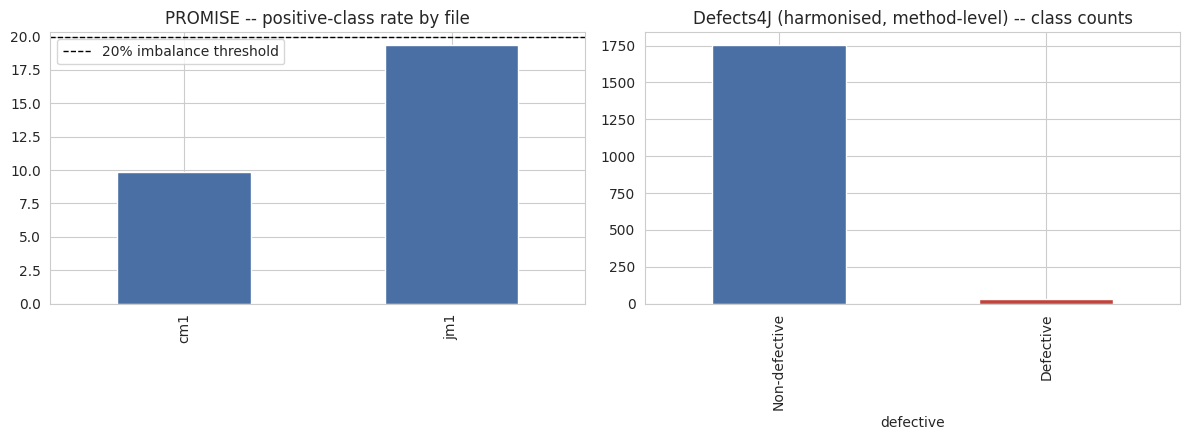

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

promise_rates = {name: to_binary(df[promise_meta[name]["label_col"]]).mean() * 100
                  for name, df in promise_tables.items()}
pd.Series(promise_rates).plot(kind="bar", ax=ax[0], color="#4A6FA5")
ax[0].axhline(20, color="black", linestyle="--", linewidth=1, label="20% imbalance threshold")
ax[0].set_title("PROMISE -- positive-class rate by file")
ax[0].legend()

if len(d4j_metric_view):
    d4j_metric_view["defective"].map({0: "Non-defective", 1: "Defective"}).value_counts().plot(
        kind="bar", ax=ax[1], color=["#4A6FA5", "#C1443C"])
ax[1].set_title("Defects4J (harmonised, method-level) -- class counts")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_distribution.png", dpi=150)
plt.show()

## 7. Pipeline A -- shared ML pre-processing utilities (Sections 3.4.1, 3.4.2)

Grid sizes are reduced under `QUICK_TEST` -- this, together with only ever touching the
*real* PROMISE/Defects4J tables (not the 566 stray files from before), is what fixes the
runtime.

In [ ]:
class CorrPruner(BaseEstimator, TransformerMixin):
    def __init__(self, thresh=0.9):
        self.thresh = thresh

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        corr = X.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        drop = [c for c in upper.columns if any(upper[c] > self.thresh)]
        self.keep_idx_ = [i for i, c in enumerate(X.columns) if c not in drop]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.iloc[:, self.keep_idx_].values

def select_features(Xtr, ytr, Xval, k=15):
    pruner = CorrPruner(0.9).fit(Xtr)
    Xtr_p = pd.DataFrame(pruner.transform(Xtr))
    Xval_p = pd.DataFrame(pruner.transform(Xval))
    n_feats = min(k, Xtr_p.shape[1])
    if n_feats < 1:
        return Xtr_p, Xval_p
    rfe = RFE(RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE), n_features_to_select=n_feats)
    rfe.fit(Xtr_p, ytr)
    return Xtr_p.loc[:, rfe.support_], Xval_p.loc[:, rfe.support_]

def make_ml_pipeline(clf, scale=False, use_smote=True):
    steps = []
    if scale:
        steps.append(("scale", StandardScaler()))
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

GRIDS = {
    "small": {
        "SVM": {"clf__C": [1, 10], "clf__kernel": ["rbf"], "clf__gamma": ["scale"]},
        "Decision Tree": {"clf__max_depth": [10, None], "clf__min_samples_split": [2, 5], "clf__criterion": ["gini"]},
        "Random Forest": {"clf__n_estimators": [100], "clf__max_depth": [None, 10], "clf__max_features": ["sqrt"]},
    },
    "full": {
        "SVM": {"clf__C": [0.1, 1, 10], "clf__kernel": ["rbf", "linear"], "clf__gamma": ["scale", "auto"]},
        "Decision Tree": {"clf__max_depth": [5, 10, 20, None], "clf__min_samples_split": [2, 5, 10],
                          "clf__criterion": ["gini", "entropy"]},
        "Random Forest": {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [None, 10, 20],
                          "clf__min_samples_split": [2, 5], "clf__max_features": ["sqrt", "log2"]},
    },
}

ML_MODELS = {
    "SVM": dict(build=lambda smote: make_ml_pipeline(SVC(probability=True, random_state=RANDOM_STATE), scale=True, use_smote=smote),
                grid=GRIDS[ML_GRID_MODE]["SVM"], search="grid"),
    "Decision Tree": dict(build=lambda smote: make_ml_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), use_smote=smote),
                           grid=GRIDS[ML_GRID_MODE]["Decision Tree"], search="grid"),
    "Random Forest": dict(build=lambda smote: make_ml_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), use_smote=smote),
                           grid=GRIDS[ML_GRID_MODE]["Random Forest"], search="random"),
}

## 8. Unified Pipeline-A CV harness (Section 3.6, 3.7)

In [ ]:
def run_pipeline_a(X, y, dataset_name, use_smote=True, n_folds=None, repeats=1):
    n_folds = n_folds or N_OUTER_ML
    cv = (RepeatedStratifiedKFold(n_splits=n_folds, n_repeats=repeats, random_state=RANDOM_STATE)
          if repeats > 1 else
          StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE))

    fold_metrics, fold_timing = {m: [] for m in ML_MODELS}, {m: [] for m in ML_MODELS}

    for name, spec in ML_MODELS.items():
        for fold_i, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
            Xtr, Xval = X.iloc[tr_idx].reset_index(drop=True), X.iloc[val_idx].reset_index(drop=True)
            ytr, yval = y[tr_idx], y[val_idx]

            Xtr_sel, Xval_sel = select_features(Xtr, ytr, Xval)
            if Xtr_sel.shape[1] == 0 or len(set(ytr)) < 2:
                continue

            pipe = spec["build"](use_smote)
            searcher = (GridSearchCV(pipe, spec["grid"], scoring="f1", cv=3, n_jobs=-1)
                        if spec["search"] == "grid" else
                        RandomizedSearchCV(pipe, spec["grid"], scoring="f1", cv=3, n_iter=5,
                                            n_jobs=-1, random_state=RANDOM_STATE))
            t0 = time.time()
            searcher.fit(Xtr_sel, ytr)
            train_time = time.time() - t0

            t0 = time.time()
            pred = searcher.predict(Xval_sel)
            infer_time = (time.time() - t0) / max(len(Xval_sel), 1)
            proba = searcher.predict_proba(Xval_sel)[:, 1]

            fold_metrics[name].append(dict(
                dataset=dataset_name, fold=fold_i,
                accuracy=accuracy_score(yval, pred),
                precision=precision_score(yval, pred, zero_division=0),
                recall=recall_score(yval, pred, zero_division=0),
                f1=f1_score(yval, pred, zero_division=0),
                auc=roc_auc_score(yval, proba) if len(set(yval)) > 1 else np.nan,
                mcc=matthews_corrcoef(yval, pred),
            ))
            fold_timing[name].append(dict(dataset=dataset_name, train_s=train_time, infer_s=infer_time))

    return fold_metrics, fold_timing

def prep_xy(df, label_col):
    id_cols = {"index", "id"}
    feats = [c for c in df.columns if c.lower() not in id_cols and c != label_col]
    X = df[feats].apply(pd.to_numeric, errors="coerce")
    X = X.fillna(X.median())
    y = to_binary(df[label_col]).values
    return X, y

## 9. Run Pipeline A -- only on the real tables (PROMISE files + harmonised Defects4J)

This loop now iterates over a handful of genuine labelled tables instead of hundreds of
stray files, which is the main fix for the runtime problem.

In [ ]:
all_fold_metrics, all_fold_timing = {}, {}

for name, df in promise_tables.items():
    X, y = prep_xy(df, promise_meta[name]["label_col"])
    if X.shape[1] == 0 or len(set(y)) < 2:
        print(f"skipping {name}: no usable numeric features or single class")
        continue
    t0 = time.time()
    is_pc2 = "pc2" in name.lower()
    if is_pc2:
        fm, ft = run_pipeline_a(X, y, name, use_smote=False, n_folds=PC2_REPEATS, repeats=PC2_REPEATS)
    else:
        fm, ft = run_pipeline_a(X, y, name, use_smote=True, n_folds=N_OUTER_ML)
    all_fold_metrics[name], all_fold_timing[name] = fm, ft
    print(f"done: {name} ({time.time()-t0:.1f}s)")

if len(d4j_metric_view) >= 20:
    Xd, yd = prep_xy(d4j_metric_view.select_dtypes(include=[np.number]).assign(defective=d4j_metric_view["defective"]), "defective")
    t0 = time.time()
    fm, ft = run_pipeline_a(Xd, yd, "Defects4J (harmonised)", use_smote=True, n_folds=N_OUTER_ML)
    all_fold_metrics["Defects4J"], all_fold_timing["Defects4J"] = fm, ft
    print(f"done: Defects4J Pipeline A ({time.time()-t0:.1f}s)")
else:
    print("Too few harmonised Defects4J methods for Pipeline A -- increase BUGS_PER_PROJECT_LIMIT.")

done: cm1 (6.6s)
done: jm1 (167.1s)
done: Defects4J Pipeline A (5.8s)


## 10. Pipeline B -- GPU-accelerated deep learning (Section 3.4.3, 3.5.2)

Runs on the Defects4J method source extracted in Section 5. Uses the GPU detected in
Section 2 automatically -- TensorFlow places ops on GPU by default when one is visible;
no extra code needed beyond the memory-growth config already set.

In [ ]:
RUN_PIPELINE_B = len(d4j_source_view) >= 50

if not RUN_PIPELINE_B:
    print("Pipeline B skipped: fewer than 50 harmonised Defects4J methods. "
          "Increase BUGS_PER_PROJECT_LIMIT / set QUICK_TEST=False and re-run Sections 4-5.")
else:
    from tensorflow.keras import layers, models, callbacks
    from sklearn.utils.class_weight import compute_class_weight

    def tokenize_source(source):
        try:
            return [tok.value for tok in javalang.tokenizer.tokenize(source)]
        except Exception:
            return source.split()

    def build_vocab(token_lists, min_freq=2):
        from collections import Counter
        counts = Counter(tok for toks in token_lists for tok in toks)
        vocab = {"<PAD>": 0, "<UNK>": 1}
        for tok, c in counts.items():
            if c >= min_freq:
                vocab[tok] = len(vocab)
        return vocab

    def encode(token_lists, vocab, max_len):
        seqs = [[vocab.get(t, vocab["<UNK>"]) for t in toks][:max_len] for toks in token_lists]
        return tf.keras.preprocessing.sequence.pad_sequences(seqs, maxlen=max_len, padding="post")

    all_tokens = d4j_source_view["source"].apply(tokenize_source)
    MAX_LEN = int(np.percentile(all_tokens.apply(len), 90)) or 200
    print("MAX_LEN:", MAX_LEN)

    def build_cnn(vocab_size, max_len):
        m = models.Sequential([
            layers.Embedding(vocab_size, 64, input_length=max_len),
            layers.Conv1D(64, 5, activation="relu"),
            layers.GlobalMaxPooling1D(),
            layers.Dropout(0.3),
            layers.Dense(32, activation="relu"),
            layers.Dense(1, activation="sigmoid"),
        ])
        m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        return m

    def build_lstm(vocab_size, max_len):
        m = models.Sequential([
            layers.Embedding(vocab_size, 64, input_length=max_len),
            layers.LSTM(64, dropout=0.3),
            layers.Dense(32, activation="relu"),
            layers.Dense(1, activation="sigmoid"),
        ])
        m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        return m

    def build_cnn_lstm(vocab_size, max_len):
        m = models.Sequential([
            layers.Embedding(vocab_size, 64, input_length=max_len),
            layers.Conv1D(64, 5, activation="relu"),
            layers.MaxPooling1D(2),
            layers.LSTM(64, dropout=0.3),
            layers.Dense(32, activation="relu"),
            layers.Dense(1, activation="sigmoid"),
        ])
        m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        return m

    DL_MODELS = {"CNN": build_cnn, "LSTM": build_lstm, "Hybrid CNN-LSTM": build_cnn_lstm}
    print("Pipeline B ready on device:", "GPU" if tf.config.list_physical_devices("GPU") else "CPU")

MAX_LEN: 148
Pipeline B ready on device: GPU


In [ ]:
if RUN_PIPELINE_B:
    y_all = d4j_source_view["defective"].values
    tokens_all = all_tokens.tolist()

    cv = StratifiedKFold(n_splits=N_OUTER_DL, shuffle=True, random_state=RANDOM_STATE)
    dl_fold_metrics = {m: [] for m in DL_MODELS}
    dl_fold_timing = {m: [] for m in DL_MODELS}

    for fold_i, (tr_idx, val_idx) in enumerate(cv.split(np.zeros(len(y_all)), y_all)):
        train_tokens = [tokens_all[i] for i in tr_idx]
        val_tokens = [tokens_all[i] for i in val_idx]
        ytr, yval = y_all[tr_idx], y_all[val_idx]
        if len(set(ytr)) < 2:
            continue

        vocab = build_vocab(train_tokens)
        Xtr = encode(train_tokens, vocab, MAX_LEN)
        Xval = encode(val_tokens, vocab, MAX_LEN)

        cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)
        class_weight = {0: cw[0], 1: cw[1]}

        for name, builder in DL_MODELS.items():
            model = builder(len(vocab), MAX_LEN)
            es = callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

            t0 = time.time()
            model.fit(Xtr, ytr, validation_split=0.15, epochs=DL_EPOCHS, batch_size=64,
                      class_weight=class_weight, callbacks=[es], verbose=0)
            train_time = time.time() - t0

            t0 = time.time()
            proba = model.predict(Xval, verbose=0).ravel()
            infer_time = (time.time() - t0) / max(len(Xval), 1)
            pred = (proba >= 0.5).astype(int)

            dl_fold_metrics[name].append(dict(
                dataset="Defects4J", fold=fold_i,
                accuracy=accuracy_score(yval, pred),
                precision=precision_score(yval, pred, zero_division=0),
                recall=recall_score(yval, pred, zero_division=0),
                f1=f1_score(yval, pred, zero_division=0),
                auc=roc_auc_score(yval, proba) if len(set(yval)) > 1 else np.nan,
                mcc=matthews_corrcoef(yval, pred),
            ))
            dl_fold_timing[name].append(dict(dataset="Defects4J", train_s=train_time, infer_s=infer_time))

    all_fold_metrics["Defects4J_DL"] = dl_fold_metrics
    all_fold_timing["Defects4J_DL"] = dl_fold_timing
    print("done: Defects4J Pipeline B (DL)")

done: Defects4J Pipeline B (DL)


## 11. Consolidated results (Section 3.7)

In [ ]:
def summarise(fold_metrics_dict):
    rows = []
    for dataset_key, model_dict in fold_metrics_dict.items():
        for model_name, records in model_dict.items():
            if not records:
                continue
            df = pd.DataFrame(records)
            agg = df[["accuracy", "precision", "recall", "f1", "auc", "mcc"]].mean()
            rows.append(dict(dataset=dataset_key, model=model_name, **agg.to_dict(), n_folds=len(df)))
    return pd.DataFrame(rows)

results_summary = summarise(all_fold_metrics)
results_summary = results_summary.sort_values(["dataset", "f1"], ascending=[True, False])
results_summary.to_csv(f"{OUT_DIR}/results_summary.csv", index=False)
results_summary

,dataset,model,accuracy,precision,recall,f1,auc,mcc,n_folds
6,Defects4J,SVM,0.793056,0.051325,0.578788,0.093902,0.722304,0.125181,3
7,Defects4J,Decision Tree,0.825580,0.033425,0.324242,0.060526,0.506733,0.055228,3
8,Defects4J,Random Forest,0.806502,0.032306,0.357576,0.059130,0.570475,0.056362,3
9,Defects4J_DL,CNN,0.915304,0.132985,0.575758,0.209597,0.861934,0.244277,3
10,Defects4J_DL,LSTM,0.893448,0.079298,0.481818,0.136064,0.667852,0.162669,3
11,Defects4J_DL,Hybrid CNN-LSTM,0.923130,0.048241,0.300000,0.083075,0.733066,0.098406,3
0,cm1,SVM,0.779116,0.215943,0.469363,0.295659,0.730544,0.205312,3
2,cm1,Random Forest,0.821285,0.185632,0.242647,0.207028,0.679034,0.112152,3
1,cm1,Decision Tree,0.775100,0.153973,0.283088,0.198504,0.560046,0.087051,3
3,jm1,SVM,0.716949,0.355553,0.568851,0.437550,0.715056,0.274613,3


## 12. Statistical significance testing (Section 3.8)

In [ ]:
from itertools import combinations

def significance_table(fold_metrics_dict, dataset_key, metric="f1"):
    frames = {m: pd.DataFrame(r)[metric].values for m, r in fold_metrics_dict.get(dataset_key, {}).items() if r}
    pairs = list(combinations(frames.keys(), 2))
    rows, raw_p = [], []
    for a, b in pairs:
        fa, fb = frames[a], frames[b]
        n = min(len(fa), len(fb))
        if n < 2:
            continue
        stat, p = wilcoxon(fa[:n], fb[:n])
        diffs = fa[:n] - fb[:n]
        r = 1 - (2 * stat) / (n * (n + 1) / 2) if n > 0 else np.nan
        rows.append(dict(pair=f"{a} vs {b}", wilcoxon_stat=stat, raw_p=p, rank_biserial_effect=r))
        raw_p.append(p)
    if not rows:
        return pd.DataFrame()
    reject, corrected_p, _, _ = multipletests(raw_p, alpha=0.05, method="holm")
    out = pd.DataFrame(rows)
    out["holm_corrected_p"] = corrected_p
    out["significant (a=0.05)"] = reject
    return out

for dataset_key in [k for k in all_fold_metrics if k != "Defects4J_DL"]:
    sig = significance_table(all_fold_metrics, dataset_key)
    if len(sig):
        print(f"--- {dataset_key} ---")
        print(sig.to_string(index=False))
        sig.to_csv(f"{OUT_DIR}/significance_{dataset_key.replace(' ', '_')}.csv", index=False)

if RUN_PIPELINE_B and "Defects4J" in all_fold_metrics:
    combined = {"Defects4J_all": {**all_fold_metrics["Defects4J"], **all_fold_metrics["Defects4J_DL"]}}
    sig_six = significance_table(combined, "Defects4J_all")
    sig_six.to_csv(f"{OUT_DIR}/significance_six_model_defects4j.csv", index=False)
    print("--- Defects4J: full six-model comparison ---")
    print(sig_six.to_string(index=False) if len(sig_six) else "not enough paired folds")

--- cm1 ---
                          pair  wilcoxon_stat  raw_p  rank_biserial_effect  holm_corrected_p  significant (a=0.05)
          SVM vs Decision Tree            0.0   0.25              1.000000              0.75                 False
          SVM vs Random Forest            0.0   0.25              1.000000              0.75                 False
Decision Tree vs Random Forest            2.0   0.75              0.333333              0.75                 False
--- jm1 ---
                          pair  wilcoxon_stat  raw_p  rank_biserial_effect  holm_corrected_p  significant (a=0.05)
          SVM vs Decision Tree            0.0   0.25              1.000000              0.75                 False
          SVM vs Random Forest            2.0   0.75              0.333333              0.75                 False
Decision Tree vs Random Forest            0.0   0.25              1.000000              0.75                 False
--- Defects4J ---
                          pair  wilcox

## 13. Visual comparison and save artefacts

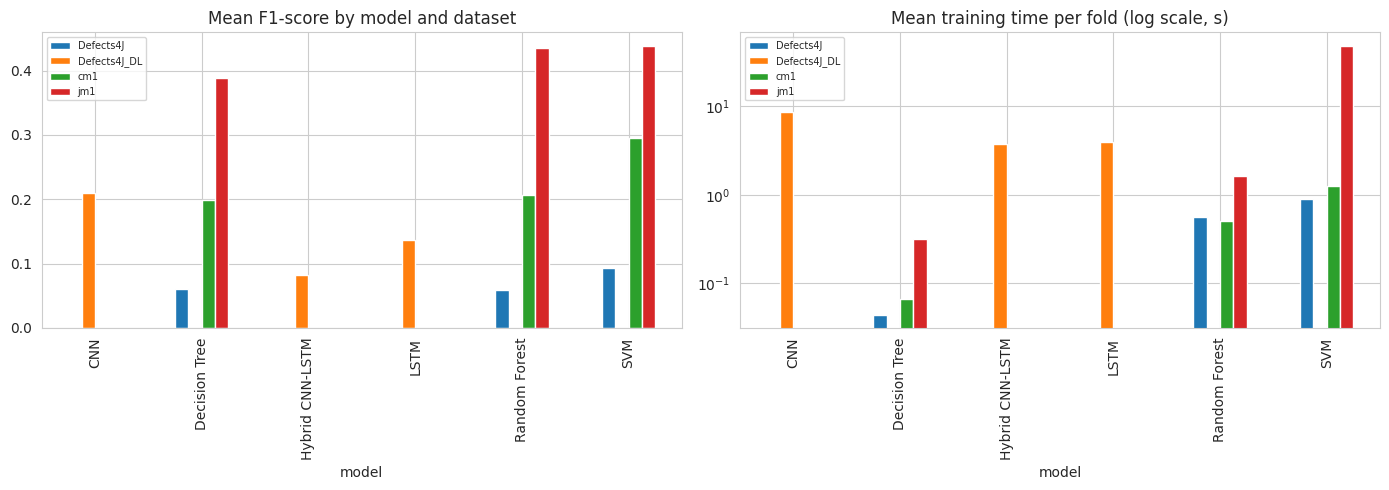

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

pivot_f1 = results_summary.pivot_table(index="model", columns="dataset", values="f1")
pivot_f1.plot(kind="bar", ax=ax[0])
ax[0].set_title("Mean F1-score by model and dataset")
ax[0].legend(fontsize=7)

timing_rows = []
for dk, models_d in all_fold_timing.items():
    for m, recs in models_d.items():
        if recs:
            timing_rows.append(dict(dataset=dk, model=m, mean_train_s=pd.DataFrame(recs)["train_s"].mean()))
timing_df = pd.DataFrame(timing_rows)
timing_df.to_csv(f"{OUT_DIR}/timing_summary.csv", index=False)
if len(timing_df):
    timing_df.pivot_table(index="model", columns="dataset", values="mean_train_s").plot(kind="bar", ax=ax[1], logy=True)
ax[1].set_title("Mean training time per fold (log scale, s)")
ax[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_model_comparison.png", dpi=150)
plt.show()

In [ ]:
with open(f"{OUT_DIR}/fold_metrics_raw.json", "w") as f:
    json.dump({k: {m: v for m, v in d.items()} for k, d in all_fold_metrics.items()}, f, default=str, indent=2)

print("Artefacts written to:", os.path.abspath(OUT_DIR))
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

Artefacts written to: /content/outputs
 - defects4j_harmonised_metrics.csv
 - defects4j_harmonised_source.csv
 - fig_distribution.png
 - fig_model_comparison.png
 - fold_metrics_raw.json
 - results_summary.csv
 - significance_Defects4J.csv
 - significance_cm1.csv
 - significance_jm1.csv
 - significance_six_model_defects4j.csv
 - timing_summary.csv


# Machine Learning and Deep Learning Models Comparison on Promise Dataset

done: cm1 ML (7.0s)


done: cm1 DL (46.1s)
done: jm1 ML (166.0s)
done: jm1 DL (65.3s)

=== PROMISE: all ML + DL model results ===
dataset           model  accuracy  precision   recall       f1      auc      mcc  n_folds
    cm1             SVM  0.779116   0.215943 0.469363 0.295659 0.730544 0.205312        3
    cm1   Decision Tree  0.775100   0.153973 0.283088 0.198504 0.560046 0.087051        3
    cm1   Random Forest  0.821285   0.185632 0.242647 0.207028 0.679034 0.112152        3
    cm1             CNN  0.891566   0.047619 0.020833 0.028986 0.424127 0.011013        3
    cm1            LSTM  0.901606   0.000000 0.000000 0.000000 0.557803 0.000000        3
    cm1 Hybrid CNN-LSTM  0.901606   0.000000 0.000000 0.000000 0.508174 0.000000        3
    jm1             SVM  0.716949   0.355553 0.568851 0.437550 0.715056 0.274613        3
    jm1   Decision Tree  0.741663   0.358999 0.425451 0.389008 0.675577 0.228379        3
    jm1   Random Forest  0.771796   0.417722 0.454416 0.435226 0.742069 0.293022  

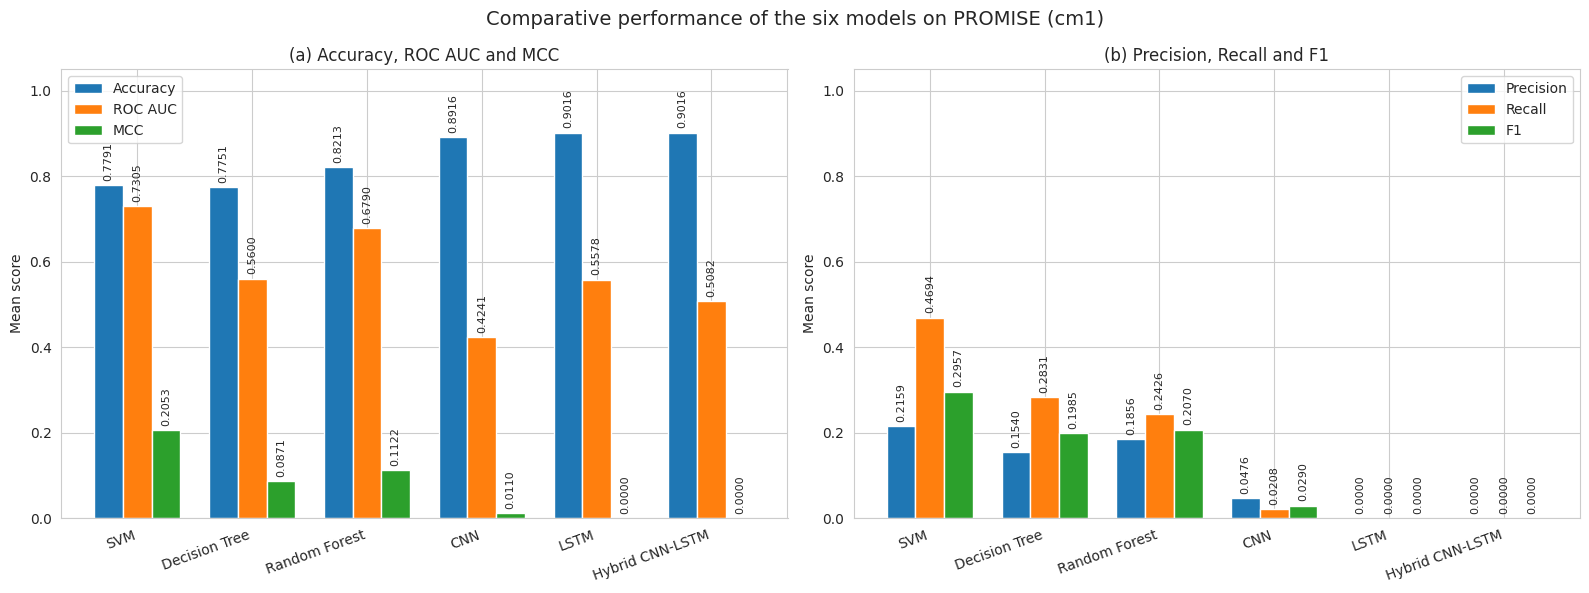

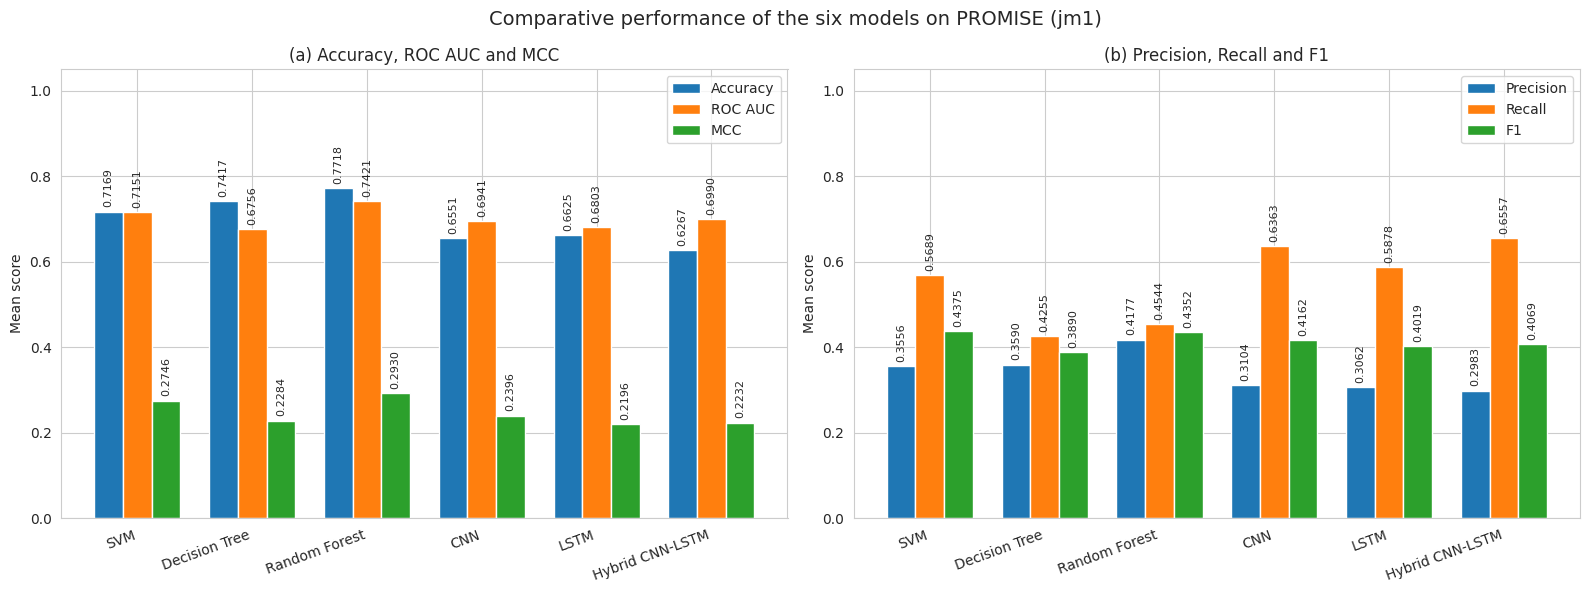

In [5]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, matthews_corrcoef)
from sklearn.utils.class_weight import compute_class_weight

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from tensorflow.keras import layers, models, callbacks

# --- Defensive fallbacks in case earlier cells weren't run this session ---
RANDOM_STATE = globals().get("RANDOM_STATE", 42)
QUICK_TEST   = globals().get("QUICK_TEST", True)
N_OUTER_ML   = globals().get("N_OUTER_ML", 3 if QUICK_TEST else 10)
N_OUTER_DL   = globals().get("N_OUTER_DL", 3 if QUICK_TEST else 10)
DL_EPOCHS    = globals().get("DL_EPOCHS", 3 if QUICK_TEST else 30)
ML_GRID_MODE = globals().get("ML_GRID_MODE", "small" if QUICK_TEST else "full")

if "to_binary" not in globals():
    def to_binary(series):
        if pd.api.types.is_bool_dtype(series) or pd.api.types.is_numeric_dtype(series):
            return series.astype(float).astype(int)
        pos_vals = {"y", "yes", "true", "1", "defective", "d", "buggy", "b", "true.", "b'yes'"}
        return series.astype(str).str.strip().str.lower().str.strip("'").isin(pos_vals).astype(int)

def prep_xy(df, label_col):
    id_cols = {"index", "id"}
    feats = [c for c in df.columns if c.lower() not in id_cols and c != label_col]
    X = df[feats].apply(pd.to_numeric, errors="coerce")
    X = X.fillna(X.median())
    y = to_binary(df[label_col]).values
    return X, y

# ============================================================
# A. ML PIPELINE (SVM, Decision Tree, Random Forest)
# ============================================================

class CorrPruner(BaseEstimator, TransformerMixin):
    def __init__(self, thresh=0.9):
        self.thresh = thresh
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        corr = X.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        drop = [c for c in upper.columns if any(upper[c] > self.thresh)]
        self.keep_idx_ = [i for i, c in enumerate(X.columns) if c not in drop]
        return self
    def transform(self, X):
        X = pd.DataFrame(X)
        return X.iloc[:, self.keep_idx_].values

def select_features(Xtr, ytr, Xval, k=15):
    pruner = CorrPruner(0.9).fit(Xtr)
    Xtr_p = pd.DataFrame(pruner.transform(Xtr))
    Xval_p = pd.DataFrame(pruner.transform(Xval))
    n_feats = min(k, Xtr_p.shape[1])
    if n_feats < 1:
        return Xtr_p, Xval_p
    rfe = RFE(RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE), n_features_to_select=n_feats)
    rfe.fit(Xtr_p, ytr)
    return Xtr_p.loc[:, rfe.support_], Xval_p.loc[:, rfe.support_]

def make_ml_pipeline(clf, scale=False, use_smote=True):
    steps = []
    if scale:
        steps.append(("scale", StandardScaler()))
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

GRIDS = {
    "small": {
        "SVM": {"clf__C": [1, 10], "clf__kernel": ["rbf"], "clf__gamma": ["scale"]},
        "Decision Tree": {"clf__max_depth": [10, None], "clf__min_samples_split": [2, 5], "clf__criterion": ["gini"]},
        "Random Forest": {"clf__n_estimators": [100], "clf__max_depth": [None, 10], "clf__max_features": ["sqrt"]},
    },
    "full": {
        "SVM": {"clf__C": [0.1, 1, 10], "clf__kernel": ["rbf", "linear"], "clf__gamma": ["scale", "auto"]},
        "Decision Tree": {"clf__max_depth": [5, 10, 20, None], "clf__min_samples_split": [2, 5, 10],
                          "clf__criterion": ["gini", "entropy"]},
        "Random Forest": {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [None, 10, 20],
                          "clf__min_samples_split": [2, 5], "clf__max_features": ["sqrt", "log2"]},
    },
}

ML_MODELS = {
    "SVM": dict(build=lambda smote: make_ml_pipeline(SVC(probability=True, random_state=RANDOM_STATE), scale=True, use_smote=smote),
                grid=GRIDS[ML_GRID_MODE]["SVM"], search="grid"),
    "Decision Tree": dict(build=lambda smote: make_ml_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), use_smote=smote),
                           grid=GRIDS[ML_GRID_MODE]["Decision Tree"], search="grid"),
    "Random Forest": dict(build=lambda smote: make_ml_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), use_smote=smote),
                           grid=GRIDS[ML_GRID_MODE]["Random Forest"], search="random"),
}

def run_pipeline_a(X, y, dataset_name, use_smote=True, n_folds=None):
    n_folds = n_folds or N_OUTER_ML
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    fold_metrics = {m: [] for m in ML_MODELS}
    fold_timing = {m: [] for m in ML_MODELS}

    for name, spec in ML_MODELS.items():
        for fold_i, (tr_idx, val_idx) in enumerate(cv.split(X, y)):
            Xtr, Xval = X.iloc[tr_idx].reset_index(drop=True), X.iloc[val_idx].reset_index(drop=True)
            ytr, yval = y[tr_idx], y[val_idx]

            Xtr_sel, Xval_sel = select_features(Xtr, ytr, Xval)
            if Xtr_sel.shape[1] == 0 or len(set(ytr)) < 2:
                continue

            pipe = spec["build"](use_smote)
            searcher = (GridSearchCV(pipe, spec["grid"], scoring="f1", cv=3, n_jobs=-1)
                        if spec["search"] == "grid" else
                        RandomizedSearchCV(pipe, spec["grid"], scoring="f1", cv=3, n_iter=5,
                                            n_jobs=-1, random_state=RANDOM_STATE))
            t0 = time.time()
            searcher.fit(Xtr_sel, ytr)
            train_time = time.time() - t0

            t0 = time.time()
            pred = searcher.predict(Xval_sel)
            infer_time = (time.time() - t0) / max(len(Xval_sel), 1)
            proba = searcher.predict_proba(Xval_sel)[:, 1]

            fold_metrics[name].append(dict(
                dataset=dataset_name, fold=fold_i,
                accuracy=accuracy_score(yval, pred),
                precision=precision_score(yval, pred, zero_division=0),
                recall=recall_score(yval, pred, zero_division=0),
                f1=f1_score(yval, pred, zero_division=0),
                auc=roc_auc_score(yval, proba) if len(set(yval)) > 1 else np.nan,
                mcc=matthews_corrcoef(yval, pred),
            ))
            fold_timing[name].append(dict(dataset=dataset_name, train_s=train_time, infer_s=infer_time))
    return fold_metrics, fold_timing

# ============================================================
# B. DL PIPELINE (CNN, LSTM, Hybrid CNN-LSTM) -- tabular version
# ============================================================

def build_cnn_tab(n_features):
    m = models.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.Conv1D(64, 3, activation="relu", padding="same"),
        layers.GlobalMaxPooling1D(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_lstm_tab(n_features):
    m = models.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.LSTM(64, dropout=0.3),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_cnn_lstm_tab(n_features):
    m = models.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.Conv1D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling1D(2, padding="same"),
        layers.LSTM(64, dropout=0.3),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

DL_MODELS_TAB = {"CNN": build_cnn_tab, "LSTM": build_lstm_tab, "Hybrid CNN-LSTM": build_cnn_lstm_tab}

def run_pipeline_b_tabular(X, y, dataset_name, n_folds=None, epochs=None):
    n_folds = n_folds or N_OUTER_DL
    epochs = epochs or DL_EPOCHS

    Xs = StandardScaler().fit_transform(X.values if hasattr(X, "values") else X)
    y = np.asarray(y)

    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    fold_metrics = {m: [] for m in DL_MODELS_TAB}
    fold_timing = {m: [] for m in DL_MODELS_TAB}

    for fold_i, (tr_idx, val_idx) in enumerate(cv.split(Xs, y)):
        Xtr, Xval = Xs[tr_idx], Xs[val_idx]
        ytr, yval = y[tr_idx], y[val_idx]
        if len(set(ytr)) < 2:
            continue

        Xtr_seq = Xtr.reshape(Xtr.shape[0], Xtr.shape[1], 1)
        Xval_seq = Xval.reshape(Xval.shape[0], Xval.shape[1], 1)

        cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)
        class_weight = {0: cw[0], 1: cw[1]}

        for name, builder in DL_MODELS_TAB.items():
            model = builder(Xtr_seq.shape[1])
            es = callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

            t0 = time.time()
            model.fit(Xtr_seq, ytr, validation_split=0.15, epochs=epochs, batch_size=32,
                      class_weight=class_weight, callbacks=[es], verbose=0)
            train_time = time.time() - t0

            t0 = time.time()
            proba = model.predict(Xval_seq, verbose=0).ravel()
            infer_time = (time.time() - t0) / max(len(Xval_seq), 1)
            pred = (proba >= 0.5).astype(int)

            fold_metrics[name].append(dict(
                dataset=dataset_name, fold=fold_i,
                accuracy=accuracy_score(yval, pred),
                precision=precision_score(yval, pred, zero_division=0),
                recall=recall_score(yval, pred, zero_division=0),
                f1=f1_score(yval, pred, zero_division=0),
                auc=roc_auc_score(yval, proba) if len(set(yval)) > 1 else np.nan,
                mcc=matthews_corrcoef(yval, pred),
            ))
            fold_timing[name].append(dict(dataset=dataset_name, train_s=train_time, infer_s=infer_time))
    return fold_metrics, fold_timing

# ============================================================
# C. RUN both pipelines on every PROMISE table
# ============================================================

promise_all_fold_metrics, promise_all_fold_timing = {}, {}

for name, df in promise_tables.items():
    X, y = prep_xy(df, promise_meta[name]["label_col"])
    if X.shape[1] == 0 or len(set(y)) < 2:
        print(f"skipping {name}: no usable numeric features or single class")
        continue

    t0 = time.time()
    ml_fm, ml_ft = run_pipeline_a(X, y, name, use_smote=True, n_folds=N_OUTER_ML)
    print(f"done: {name} ML ({time.time()-t0:.1f}s)")

    t0 = time.time()
    dl_fm, dl_ft = run_pipeline_b_tabular(X, y, name, n_folds=N_OUTER_DL, epochs=DL_EPOCHS)
    print(f"done: {name} DL ({time.time()-t0:.1f}s)")

    # merge ML + DL dicts for this dataset into one 6-model dict
    promise_all_fold_metrics[name] = {**ml_fm, **dl_fm}
    promise_all_fold_timing[name] = {**ml_ft, **dl_ft}

# ============================================================
# D. RESULTS TABLE
# ============================================================

def summarise(fold_metrics_dict):
    rows = []
    for dataset_key, model_dict in fold_metrics_dict.items():
        for model_name, records in model_dict.items():
            if not records:
                continue
            df = pd.DataFrame(records)
            agg = df[["accuracy", "precision", "recall", "f1", "auc", "mcc"]].mean()
            rows.append(dict(dataset=dataset_key, model=model_name, **agg.to_dict(), n_folds=len(df)))
    return pd.DataFrame(rows)

promise_results_summary = summarise(promise_all_fold_metrics)
print("\n=== PROMISE: all ML + DL model results ===")
print(promise_results_summary.to_string(index=False))

# ============================================================
# E. VISUALIZATION -- 2-panel comparison per dataset (6 models each)
# ============================================================

model_order = ["SVM", "Decision Tree", "Random Forest", "CNN", "LSTM", "Hybrid CNN-LSTM"]

for dataset_name in promise_results_summary["dataset"].unique():
    sub = promise_results_summary[promise_results_summary["dataset"] == dataset_name]
    sub = sub.set_index("model").reindex(model_order).dropna(how="all").reset_index()

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))

    x = np.arange(len(sub))
    width = 0.25

    for i, (col, label, color) in enumerate([
        ("accuracy", "Accuracy", "#1f77b4"), ("auc", "ROC AUC", "#ff7f0e"), ("mcc", "MCC", "#2ca02c")
    ]):
        bars = ax[0].bar(x + (i - 1) * width, sub[col], width, label=label, color=color)
        for b, v in zip(bars, sub[col]):
            ax[0].text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.4f}", ha="center", va="bottom",
                       fontsize=8, rotation=90)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(sub["model"], rotation=20, ha="right")
    ax[0].set_ylim(0, 1.05)
    ax[0].set_ylabel("Mean score")
    ax[0].set_title("(a) Accuracy, ROC AUC and MCC")
    ax[0].legend()

    for i, (col, label, color) in enumerate([
        ("precision", "Precision", "#1f77b4"), ("recall", "Recall", "#ff7f0e"), ("f1", "F1", "#2ca02c")
    ]):
        bars = ax[1].bar(x + (i - 1) * width, sub[col], width, label=label, color=color)
        for b, v in zip(bars, sub[col]):
            ax[1].text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.4f}", ha="center", va="bottom",
                       fontsize=8, rotation=90)
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(sub["model"], rotation=20, ha="right")
    ax[1].set_ylim(0, 1.05)
    ax[1].set_ylabel("Mean score")
    ax[1].set_title("(b) Precision, Recall and F1")
    ax[1].legend()

    fig.suptitle(f"Comparative performance of the six models on PROMISE ({dataset_name})", fontsize=14)
    fig.tight_layout()
    plt.show()

# merge into the notebook's main results dict too, if it exists
if "all_fold_metrics" in globals():
    for k, v in promise_all_fold_metrics.items():
        all_fold_metrics[f"{k}_full"] = v
    for k, v in promise_all_fold_timing.items():
        all_fold_timing[f"{k}_full"] = v